In [15]:
import json

# Librerías de terceros
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


In [16]:
df = pd.read_csv('../datasets/df_procesado.csv')
df.shape

(193050, 82)

In [17]:
# 1. Asegurarte de que la columna issue_d sea de tipo datetime
df["issue_d"] = pd.to_datetime(df["issue_d"])

# 2. Ordenar cronológicamente
df = df.sort_values("issue_d").reset_index(drop=True)

# 3. Encontrar el índice del 80%
split_idx = int(len(df) * 0.8)

# 4. Ver la fecha exacta donde se divide el conjunto
fecha_corte = df.loc[split_idx, "issue_d"]

print(f"Total de registros: {len(df)}")
print(f"El conjunto de entrenamiento va desde: {df['issue_d'].min().strftime('%Y-%m')} hasta {fecha_corte.strftime('%Y-%m')}")
print(f"El conjunto de validación va desde: {fecha_corte.strftime('%Y-%m')} hasta {df['issue_d'].max().strftime('%Y-%m')}")

Total de registros: 193050
El conjunto de entrenamiento va desde: 2012-08 hasta 2014-10
El conjunto de validación va desde: 2014-10 hasta 2015-12


In [18]:
# 1. Ordenar el DataFrame cronológicamente por la fecha de originación
df = df.sort_values("issue_d").reset_index(drop=True)

# 2. Definir el punto de corte (ej: 80% más antiguo para entrenar, 20% más reciente para validar)
split_idx = int(len(df) * 0.8)

# 3. Separar X e Y (asegúrate de excluir 'issue_d' de las features ya que es un datetime)
features = [col for col in df.columns if col not in ["loan_status", "issue_d"]]

X = df[features]
y = df["loan_status"]

# 4. Partición temporal pura (sin mezclar ni estratificar)
X_train = X.iloc[:split_idx]
X_val = X.iloc[split_idx:]

y_train = y.iloc[:split_idx]
y_val = y.iloc[split_idx:]

# 5. Escalado estándar (ajustando únicamente con train para evitar fuga de datos)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

print(f"Train temporal: {X_train.shape} | Val temporal: {X_val.shape}")

Train temporal: (154440, 80) | Val temporal: (38610, 80)


In [19]:
print("Distribución de la variable respuesta en los datos de entrenamiento:")
print(y_train.value_counts(normalize=True))
print("\n")
print("Distribución de la variable respuesta en los datos de validación:")
print(y_val.value_counts(normalize=True))

Distribución de la variable respuesta en los datos de entrenamiento:
loan_status
0    0.772015
1    0.227985
Name: proportion, dtype: float64


Distribución de la variable respuesta en los datos de validación:
loan_status
0    0.746827
1    0.253173
Name: proportion, dtype: float64


In [20]:
# Selecciona GPU si está disponible, de lo contrario usa CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Muestra el dispositivo que se está utilizando
print(f"Usando: {device}")

Usando: cpu


In [21]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_val)

In [22]:
modelo = LogisticRegression(
    max_iter=5000,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

modelo.fit(X_train_scaled, y_train)
print("\nModelo entrenado ✓")

/home/tomasgomez/Github/RedesNeuronales_Trabajo2/.venv/lib64/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)



Modelo entrenado ✓


In [23]:
y_pred = modelo.predict(X_test_scaled)
y_prob = modelo.predict_proba(X_test_scaled)[:, 1]

In [24]:
print("\n── Classification Report ──────────────────────────────────")
print(classification_report(y_val, y_pred,
                             target_names=["No Default (0)", "Default (1)"]))
print(f"ROC-AUC: {roc_auc_score(y_val, y_prob):.4f}")


── Classification Report ──────────────────────────────────
                precision    recall  f1-score   support

No Default (0)       0.85      0.65      0.74     28835
   Default (1)       0.39      0.66      0.49      9775

      accuracy                           0.65     38610
     macro avg       0.62      0.65      0.61     38610
  weighted avg       0.73      0.65      0.67     38610

ROC-AUC: 0.7075


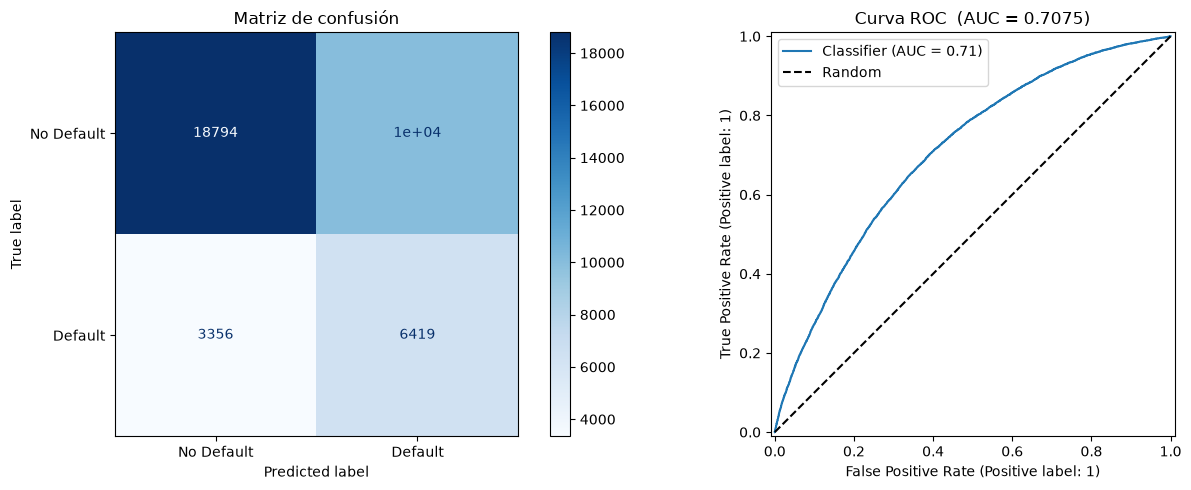

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_val, y_pred,
    display_labels=["No Default", "Default"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Matriz de confusión")

# Curva ROC
RocCurveDisplay.from_predictions(y_val, y_prob, ax=axes[1])
axes[1].set_title(f"Curva ROC  (AUC = {roc_auc_score(y_val, y_prob):.4f})")
axes[1].plot([0, 1], [0, 1], "k--", label="Random")
axes[1].legend()

plt.tight_layout()
plt.show()


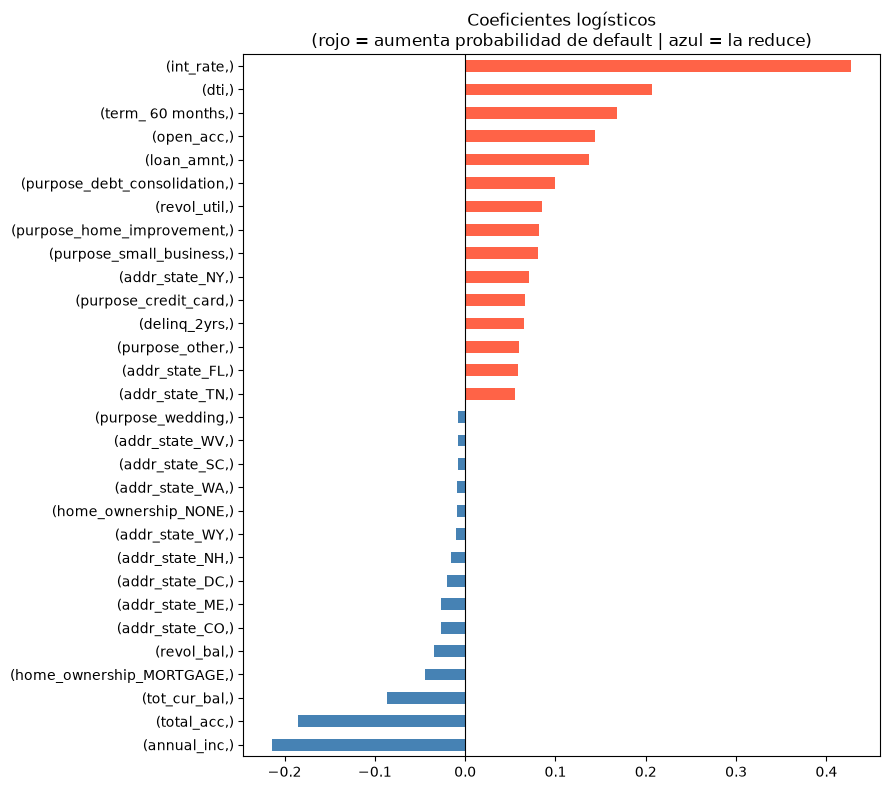


Top 10 variables que MÁS aumentan default:
int_rate                      0.427279
dti                           0.207220
term_ 60 months               0.168306
open_acc                      0.143586
loan_amnt                     0.137341
purpose_debt_consolidation    0.099235
revol_util                    0.085514
purpose_home_improvement      0.081211
purpose_small_business        0.080091
addr_state_NY                 0.070535

Top 10 variables que MÁS reducen default:
addr_state_WY             -0.010198
addr_state_NH             -0.015397
addr_state_DC             -0.020097
addr_state_ME             -0.026254
addr_state_CO             -0.027029
revol_bal                 -0.034989
home_ownership_MORTGAGE   -0.044901
tot_cur_bal               -0.086317
total_acc                 -0.184685
annual_inc                -0.213447


In [27]:
coeficientes = pd.Series(
    modelo.coef_[0],
    index=[X.columns]
).sort_values(ascending=False)

# Top 15 positivos y negativos
top_n = 15
top_coefs = pd.concat([
    coeficientes.head(top_n),
    coeficientes.tail(top_n)
]).sort_values()

colores = ["steelblue" if v < 0 else "tomato" for v in top_coefs]

top_coefs.plot(kind="barh", figsize=(9, 8), color=colores)
plt.title("Coeficientes logísticos\n"
          "(rojo = aumenta probabilidad de default | "
          "azul = la reduce)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

print("\nTop 10 variables que MÁS aumentan default:")
print(coeficientes.head(10).to_string())

print("\nTop 10 variables que MÁS reducen default:")
print(coeficientes.tail(10).to_string())
